In [ ]:
# Notebook setup: locate the project and provide the source notebook's shared data context.
from pathlib import Path
import os
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "Project_machine_notebook.ipynb").is_file():
    if (PROJECT_ROOT.parent / "Project_machine_notebook.ipynb").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Open/run this notebook with the project folder as the working directory.")
DATA_DIR = PROJECT_ROOT / "Datasets"
os.chdir(DATA_DIR)
_df_raw = pd.read_csv("raw_football_dataset.csv")
_df_work = _df_raw.copy()
if "Expected goals (xG)" in _df_work and {"Shots on target", "Shots off target"}.issubset(_df_work.columns):
    _estimated_xg = _df_work["Shots on target"] * 0.3 + _df_work["Shots off target"] * 0.1
    _df_work.loc[_df_work["Expected goals (xG)"].eq(0), "Expected goals (xG)"] = _estimated_xg
_missing_limit = int(0.70 * len(_df_work))
_df_work = _df_work.drop(columns=_df_work.columns[_df_work.isna().sum().gt(_missing_limit)])
df2 = _df_work.dropna().drop_duplicates()
df = _df_raw.copy()
CLEANED_DATA_PATH = DATA_DIR / "cleaned_raw_football_dataset.csv"
df2.to_csv(CLEANED_DATA_PATH, index=False)


## **Feature engineering (Skewness)**

In [41]:
skew_report = df2.select_dtypes(include=['number']).skew().sort_values(ascending=False)
print(skew_report)

Red cards              3.255979
Shots off target       1.098589
Goals for              1.032724
Goals against          1.032724
Expected goals (xG)    0.827768
Shots on target        0.800950
Corner kicks           0.794094
Total shots            0.681679
Yellow cards           0.653782
Fouls                  0.380456
dtype: float64


Skewness graph before and after transformation using sqrt for Cleaned dataset

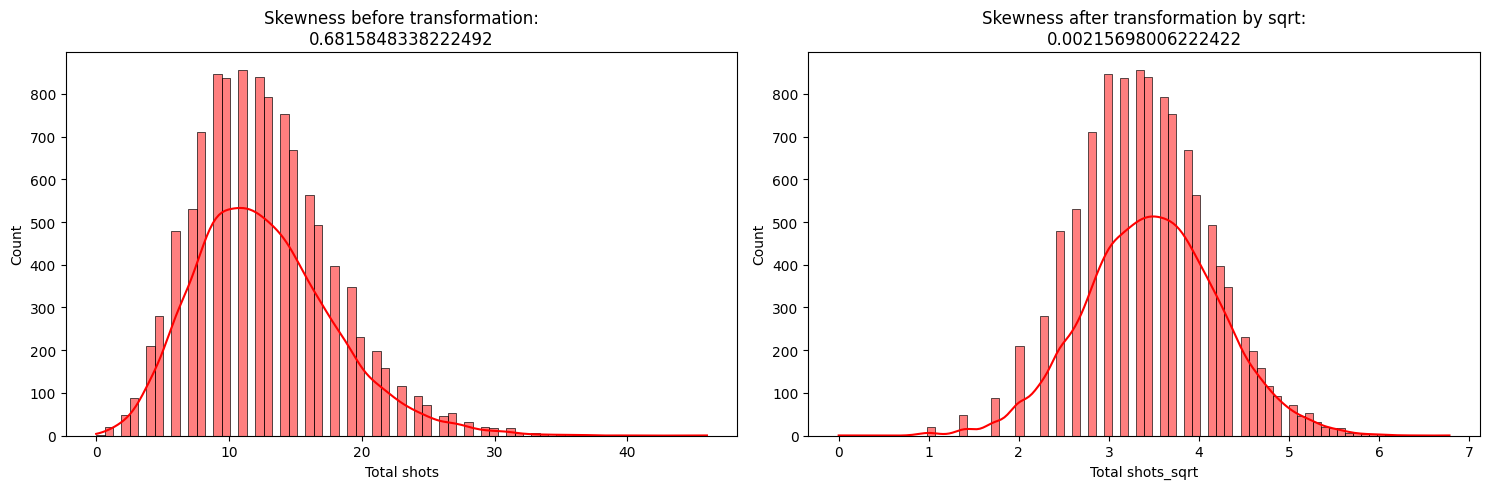

In [42]:
plt.figure(figsize=(15,5))

#Skewness Graph before transformation for df2 (cleaned dataframe)
plt.subplot(1,2,1)
s=skew(df2["Total shots"])
sns.histplot(df2["Total shots"],kde=True,color="red")
plt.title("Skewness before transformation:\n"+str(s))

#Skewness Graph after transformation for df2 (cleaned dataframe)
plt.subplot(1,2,2)
df2["Total shots_sqrt"] = np.sqrt(df2["Total shots"])
s2=skew(df2["Total shots_sqrt"])
sns.histplot(df2["Total shots_sqrt"],kde=True,color="red")
plt.title("Skewness after transformation by sqrt:\n"+str(s2))


plt.tight_layout()
plt.show()

Skewness graph before and after transformation using log for Cleaned dataset*


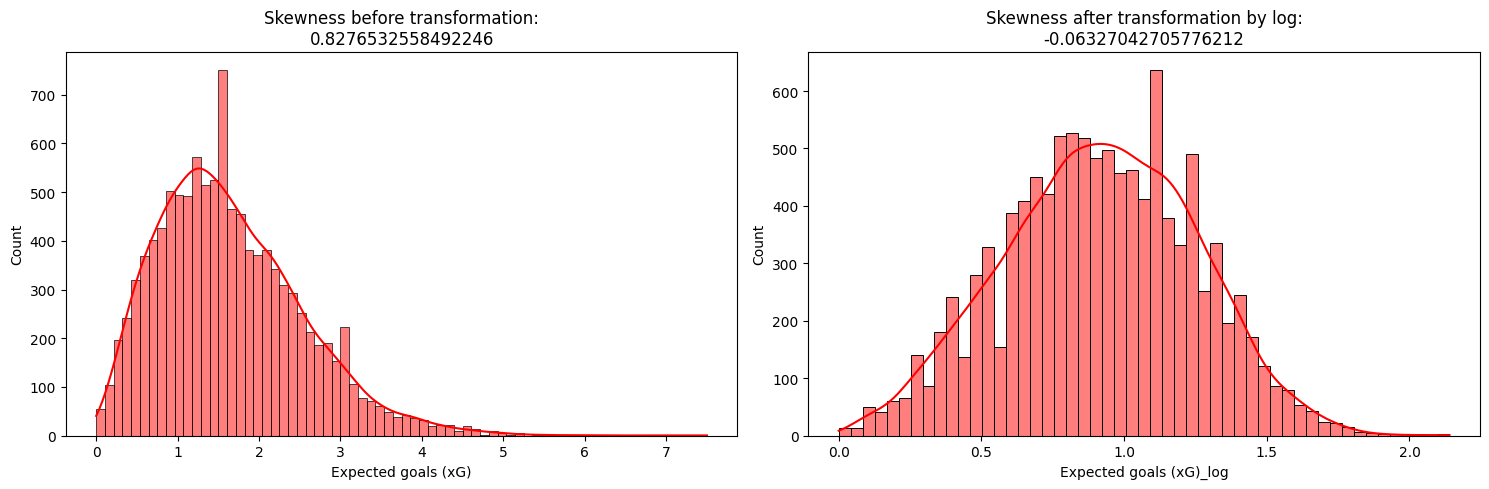

In [43]:
plt.figure(figsize=(15,5))

#Skewness Graph before transformation for df2 (cleaned dataframe)
plt.subplot(1,2,1)
s=skew(df2["Expected goals (xG)"])
sns.histplot(df2["Expected goals (xG)"],kde=True,color="red")
plt.title("Skewness before transformation:\n"+str(s))

#Skewness Graph after transformation for df2 (cleaned dataframe)
plt.subplot(1,2,2)
df2["Expected goals (xG)_log"] = np.log1p(df2["Expected goals (xG)"])
s2=skew(df2["Expected goals (xG)_log"])
sns.histplot(df2["Expected goals (xG)_log"],kde=True,color="red")
plt.title("Skewness after transformation by log:\n"+str(s2))


plt.tight_layout()
plt.show()

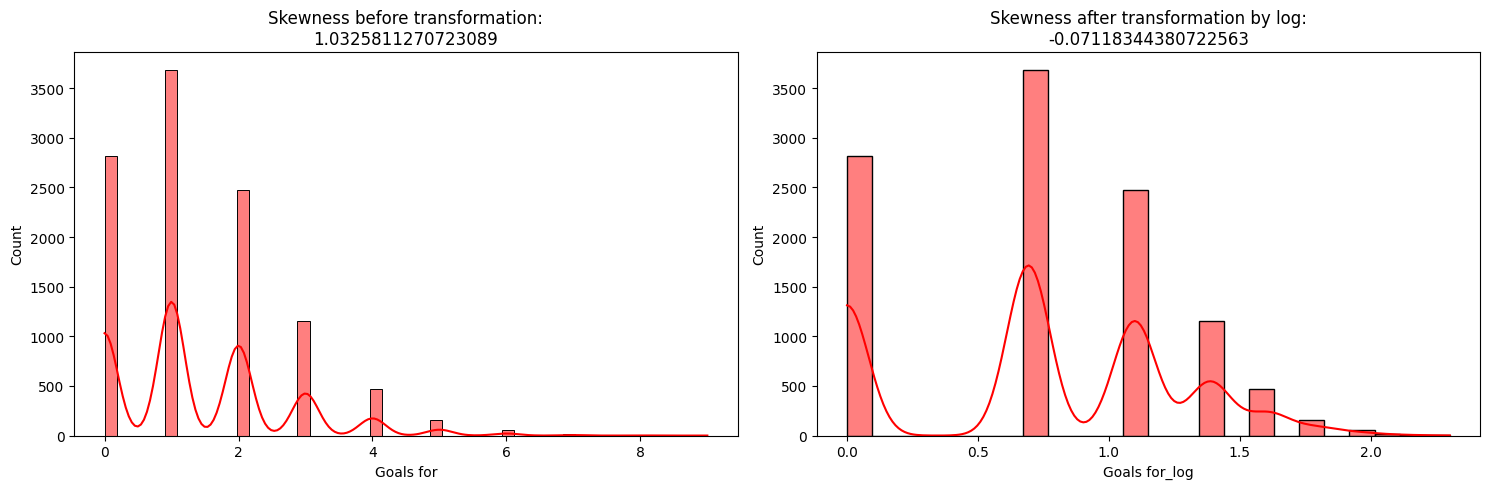

In [44]:
plt.figure(figsize=(15,5))

#Skewness Graph before transformation for df2 (cleaned dataframe)
plt.subplot(1,2,1)
s=skew(df2["Goals for"])
sns.histplot(df2["Goals for"],kde=True,color="red")
plt.title("Skewness before transformation:\n"+str(s))

#Skewness Graph after transformation for df2 (cleaned dataframe)
plt.subplot(1,2,2)
df2["Goals for_log"] = np.log1p(df2["Goals for"])
s2=skew(df2["Goals for_log"])
sns.histplot(df2["Goals for_log"],kde=True,color="red")
plt.title("Skewness after transformation by log:\n"+str(s2))


plt.tight_layout()
plt.show()

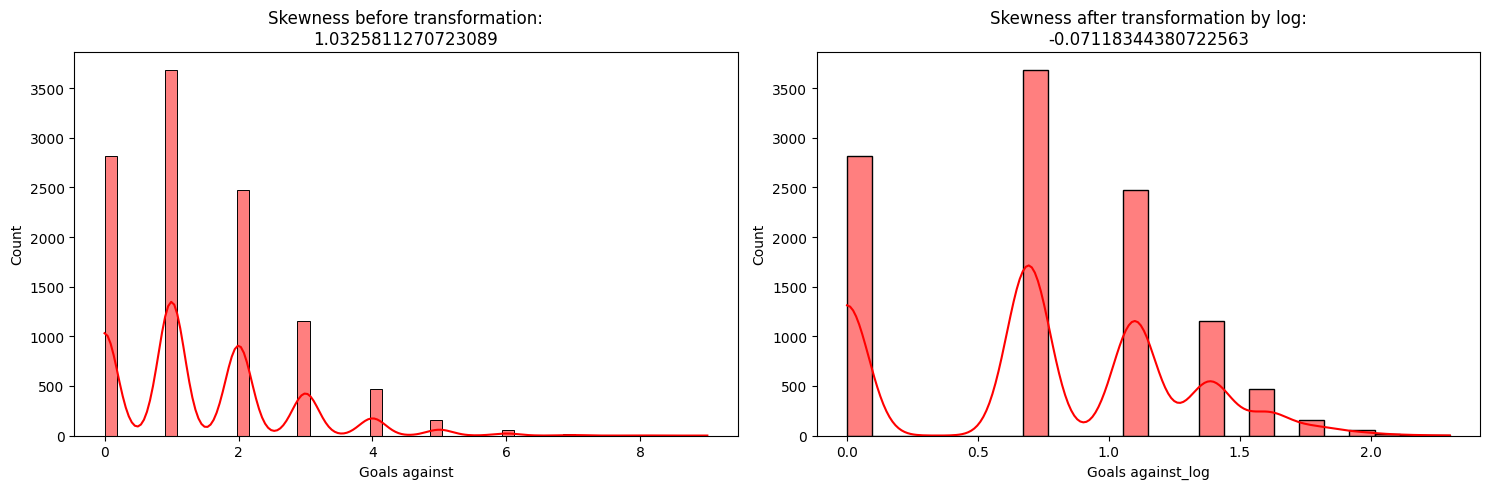

In [45]:
plt.figure(figsize=(15,5))

#Skewness Graph before transformation for df2 (cleaned dataframe)
plt.subplot(1,2,1)
s=skew(df2["Goals against"])
sns.histplot(df2["Goals against"],kde=True,color="red")
plt.title("Skewness before transformation:\n"+str(s))

#Skewness Graph after transformation for df2 (cleaned dataframe)
plt.subplot(1,2,2)
df2["Goals against_log"] = np.log1p(df2["Goals against"])
s2=skew(df2["Goals against_log"])
sns.histplot(df2["Goals against_log"],kde=True,color="red")
plt.title("Skewness after transformation by log:\n"+str(s2))


plt.tight_layout()
plt.show()